# Phân tích baseline (YOLOv5, OSNet, DeepSORT)

In [1]:
import os, sys, time, warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT    = os.path.abspath("")                       # SoccerMOT_Baseline/
BASE    = os.path.dirname(ROOT)
RESULTS = os.path.join(BASE, "results")
VIDEOS  = os.path.join(BASE, "Data", "wide_view", "videos")
GT_DIR  = os.path.join(BASE, "Data", "wide_view", "annotations")
TEST_VIDEOS = sorted(os.listdir(VIDEOS))[-6:] if os.path.isdir(VIDEOS) else []
sys.path.insert(0, ROOT)

mot = pd.read_csv(os.path.join(RESULTS, "mot_test_per_video.csv"), keep_default_na=False)
NAMES = {"YOLOv5 (COCO)": "Baseline", "YOLOv5 (retrained)": "Baseline (trained)"}
bl  = mot[mot.detector.isin(NAMES)].assign(pipeline=lambda d: d.detector.map(NAMES))
e2e = mot.query("detector == 'YOLO26' & extractor == 'None' & tracker == 'ByteTrack' & gta").assign(pipeline="E2ESoTrack (optimal)")
cmp = pd.concat([bl, e2e])
ORDER = ["Baseline", "Baseline (trained)", "E2ESoTrack (optimal)"]

ORANGE, AQUA, BLUE, GRAY = "#eb6834", "#1baf7a", "#2a78d6", "#9a9a96"
COL = {"Baseline": ORANGE, "Baseline (trained)": AQUA, "E2ESoTrack (optimal)": BLUE}
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold"})
short = lambda v: v.split("_")[-2] + "–" + v.split("_")[-1][:4]

## 1. Kết quả MOT trên tập test

In [2]:
t4 = cmp.groupby("pipeline")[["MOTA", "MOTP", "IDF1", "HOTA", "IDs", "FP", "FN"]].mean().reindex(ORDER).round(2)
t4

,MOTA,MOTP,IDF1,HOTA,IDs,FP,FN
pipeline,,,,,,,
Baseline,3.07,64.69,14.38,5.96,3.50,1642.33,14347.83
Baseline (trained),54.00,70.99,45.50,13.79,34.50,2112.17,5443.33
E2ESoTrack (optimal),68.26,70.22,65.90,31.34,12.33,715.50,4508.67


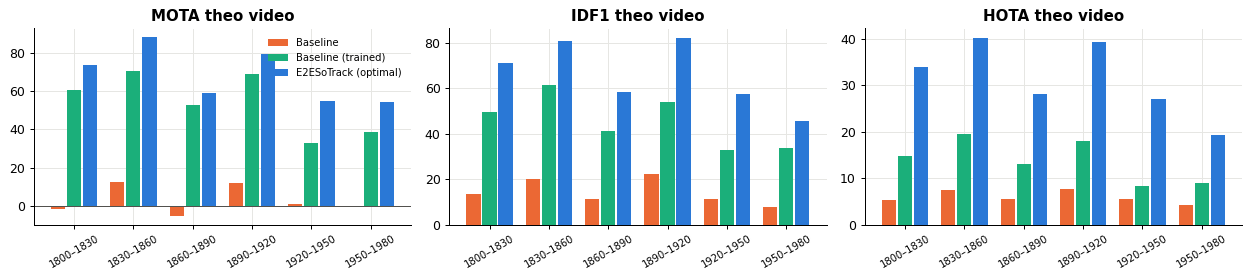

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=False)
vids = sorted(cmp.video.unique()); w = 0.27
for ax, m in zip(axes, ["MOTA", "IDF1", "HOTA"]):
    for k, p in enumerate(ORDER):
        v = cmp[cmp.pipeline == p].set_index("video").loc[vids, m]
        ax.bar(np.arange(len(vids)) + (k - 1) * w, v, width=w - 0.03, color=COL[p], label=p)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_xticks(range(len(vids))); ax.set_xticklabels([short(v) for v in vids], rotation=30, fontsize=8)
    ax.set_title(f"{m} theo video")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 2. Detection và tracking

In [4]:
from src.detector import Detector as BaselineDetector
from src.compute_metrics import load_gt_from_csv, _match_detections
from ultralytics import YOLO

class YOLO26Ref:                                     # giống PipelineMOT/src/detector.py (conf 0.4, iou 0.5, imgsz 1600)
    def __init__(self, path):
        self.model = YOLO(path).to("cuda" if __import__("torch").cuda.is_available() else "cpu")
    def detect(self, img):
        r = self.model(img, conf=0.4, iou=0.5, imgsz=1600, save=False, verbose=False)[0]
        return [[*map(int, b.xyxy[0]), float(b.conf[0])] for b in r.boxes]

STEP = 25
H_BINS, H_LBL = [0, 35, 45, 55, 200], ["<35 px", "35–45", "45–55", "≥55 px"]

def eval_detector(det, videos, step=STEP):
    rows, times = [], []
    det.detect(np.zeros((1000, 6500, 3), np.uint8))
    for v in videos:
        gt  = load_gt_from_csv(os.path.join(GT_DIR, os.path.splitext(v)[0] + ".csv"))
        cap = cv2.VideoCapture(os.path.join(VIDEOS, v)); f = 0
        while cap.grab():
            if f % step == 0:
                _, img = cap.retrieve()
                t0 = time.time(); dets = det.detect(img); times.append(time.time() - t0)
                g = [b[:4] for b in gt.get(f + 1, [])]; p = [list(b[:4]) for b in dets]
                matches, _, un_p = _match_detections(g, p, 0.5); hit = {i for i, _ in matches}
                rows += [dict(video=v, frame=f, kind="gt", h=b[3] - b[1], tp=i in hit) for i, b in enumerate(g)]
                rows += [dict(video=v, frame=f, kind="pred", h=b[3] - b[1], tp=j not in un_p) for j, b in enumerate(p)]
            f += 1
        cap.release()
    return pd.DataFrame(rows), float(np.median(times))

M_DIR = os.path.join(ROOT, "src", "models")
dets = {"Baseline": BaselineDetector("yolov5_hub", os.path.join(M_DIR, "yolov5m.pt"), conf=0.4, iou=0.5, imgsz=1600),
        "Baseline (trained)": BaselineDetector("yolov5", os.path.join(M_DIR, "best.pt"), conf=0.4, iou=0.5, imgsz=1600),
        "E2ESoTrack (optimal)": YOLO26Ref(os.path.join(BASE, "PipelineMOT", "models", "best_yolo26.pt"))}
det_res = {k: eval_detector(d, TEST_VIDEOS) for k, d in dets.items()}
%matplotlib inline

rows = []
for name, (df, t) in det_res.items():
    g, p = df[df.kind == "gt"], df[df.kind == "pred"]
    n_frames = df.groupby(["video", "frame"]).ngroups
    rows.append({"Pipeline": name,
                 "Detector": {"Baseline": "YOLOv5m (COCO)", "Baseline (trained)": "YOLOv5 (retrained)", "E2ESoTrack (optimal)": "YOLO26"}[name],
                 "Recall": g.tp.mean(), "Precision": p.tp.mean(),
                 "FP / frame: detector": (~p.tp).sum() / n_frames,
                 "FP / frame: sau tracking": t4.loc[name, "FP"] / 750,
                 "ms / frame": 1000 * t})
pd.DataFrame(rows).set_index("Pipeline").round(3)

[Detector] YOLOv5-hub loaded | model=SoccerMOT_Baseline\src\models\yolov5m.pt | device=cuda | conf=0.4 iou=0.5 imgsz=1600
[Detector] YOLOv5-ultralytics loaded | model=SoccerMOT_Baseline\src\models\best.pt | device=cuda | conf=0.4 iou=0.5 imgsz=1600


,Detector,Recall,Precision,FP / frame: detector,FP / frame: sau tracking,ms / frame
Pipeline,,,,,,
Baseline,YOLOv5m (COCO),0.289,0.671,3.117,2.190,53.894
Baseline (trained),YOLOv5 (retrained),0.892,0.954,0.950,2.816,81.034
E2ESoTrack (optimal),YOLO26,0.853,0.910,1.856,0.954,84.166


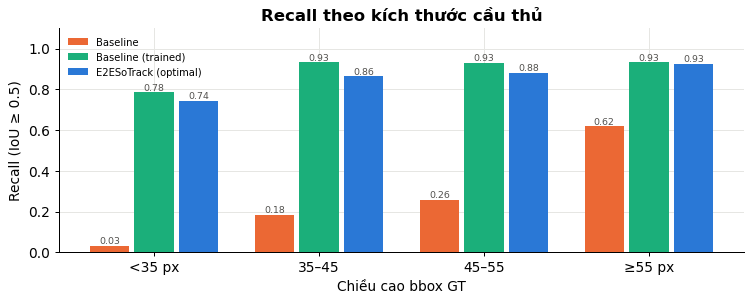

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.5)); w = 0.27
for k, (name, (df, _)) in enumerate(det_res.items()):
    g = df[df.kind == "gt"].assign(bin=lambda t: pd.cut(t.h, H_BINS, labels=H_LBL, right=False))
    r = g.groupby("bin", observed=False).tp.mean()
    x = np.arange(len(H_LBL)) + (k - 1) * w
    ax.bar(x, r.values, width=w - 0.03, color=COL[name], label=name)
    for xi, yi in zip(x, r.values): ax.text(xi, yi + 0.01, f"{yi:.2f}", ha="center", fontsize=7.5, color="#52514e")
ax.set_xticks(range(len(H_LBL))); ax.set_xticklabels(H_LBL); ax.set_ylim(0, 1.1)
ax.set_xlabel("Chiều cao bbox GT"); ax.set_ylabel("Recall (IoU ≥ 0.5)"); ax.set_title("Recall theo kích thước cầu thủ")
ax.legend(frameon=False, fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

## 3. Số ID và IDF1

In [6]:
import pickle
P = os.path.join(BASE, "Output", "pitch_eval")
files = {"Baseline": "tracks_baseline.pkl", "Baseline (trained)": "tracks_baseline_trained.pkl", "E2ESoTrack (optimal)": "tracks_e2e_best.pkl"}
if all(os.path.exists(os.path.join(P, f)) for f in files.values()):
    tr = {k: pickle.load(open(os.path.join(P, f), "rb")) for k, f in files.items()}
    rows = []
    for v in sorted(tr["Baseline"]):
        gt = load_gt_from_csv(os.path.join(GT_DIR, os.path.splitext(v)[0] + ".csv"))
        row = {"clip": short(v), "cầu thủ (GT)": len({b[4] for bs in gt.values() for b in bs})}
        for k in files:
            lens = [len(t["frames"]) for t in tr[k][v].values()]
            row[f"{k}: #ID"] = len(lens)
            row[f"{k}: độ dài TB (frame)"] = int(np.mean(lens)) if lens else 0
        rows.append(row)
    ids = pd.DataFrame(rows).set_index("clip")
    display(ids)
else:
    print("Chưa có tracks trong Output/pitch_eval/")

,cầu thủ (GT),Baseline: #ID,Baseline: độ dài TB (frame),Baseline (trained): #ID,Baseline (trained): độ dài TB (frame),E2ESoTrack (optimal): #ID,E2ESoTrack (optimal): độ dài TB (frame)
clip,,,,,,,
0720–0750,22,10,299,86,140,23,563
0750–0780,22,6,443,59,191,21,536
0780–0810,22,18,214,66,212,24,611
0810–0840,22,30,152,75,191,28,542
0840–0870,22,20,181,72,177,25,539
0870–0900,22,38,161,71,198,26,584


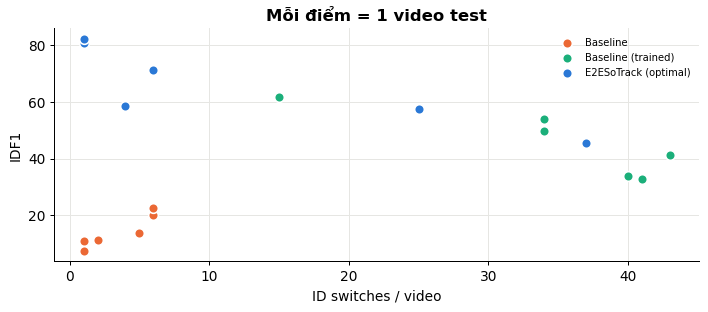

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for p in ORDER:
    sub = cmp[cmp.pipeline == p]
    ax.scatter(sub.IDs, sub.IDF1, s=60, color=COL[p], label=p, edgecolor="white", linewidth=1.3)
ax.set_xlabel("ID switches / video"); ax.set_ylabel("IDF1"); ax.set_title("Mỗi điểm = 1 video test")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

## 4. Tọa độ trên sân so với GNSS

,Pitch-HOTA,E_1to1,E_frame
Pipeline,,,
Oracle (GT boxes),64.09,3.53,3.47
Baseline,16.34,5.34,4.86
Baseline (trained),35.22,6.01,3.83
YOLO26 + ByteTrack,47.60,4.80,3.89
YOLO26 + ByteTrack + GTA,48.88,4.53,3.89


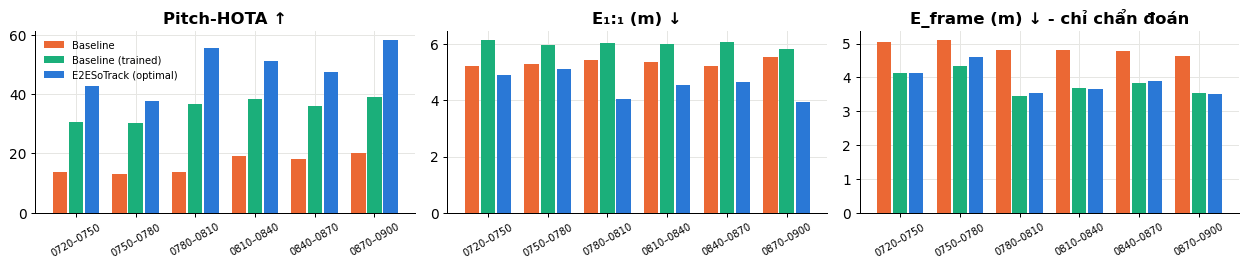

In [8]:
pe = pd.read_csv(os.path.join(RESULTS, "pitch_eval_summary.csv")).set_index("Pipeline")
pv = pd.read_csv(os.path.join(RESULTS, "pitch_eval_per_video.csv"))
display(pe.round(2))

name = {"Baseline": "Baseline", "Baseline (trained)": "Baseline (trained)", "YOLO26 + ByteTrack + GTA": "E2ESoTrack (optimal)"}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.1))
clips = sorted(pv.video.unique()); w = 0.27
for ax, m, lab in zip(axes, ["Pitch-HOTA", "E_1to1", "E_frame"], ["Pitch-HOTA ↑", "E₁:₁ (m) ↓", "E_frame (m) ↓ - chỉ chẩn đoán"]):
    for k, (src, p) in enumerate(name.items()):
        v = pv[pv.Pipeline == src].set_index("video").loc[clips, m]
        ax.bar(np.arange(len(clips)) + (k - 1) * w, v, width=w - 0.03, color=COL[p], label=p)
    ax.set_xticks(range(len(clips))); ax.set_xticklabels([short(c) for c in clips], rotation=30, fontsize=8); ax.set_title(lab)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 5. Tổng hợp

In [9]:
s = t4[["MOTA", "IDF1", "HOTA", "IDs"]]
steps = pd.DataFrame({
    "Baseline → Baseline (trained)  [huấn luyện lại detector]": s.loc["Baseline (trained)"] - s.loc["Baseline"],
    "Baseline (trained) → E2ESoTrack  [YOLO26 + ByteTrack + GTA]": s.loc["E2ESoTrack (optimal)"] - s.loc["Baseline (trained)"],
}).T.round(2)
steps

,MOTA,IDF1,HOTA,IDs
Baseline → Baseline (trained) [huấn luyện lại detector],50.93,31.12,7.83,31.00
Baseline (trained) → E2ESoTrack [YOLO26 + ByteTrack + GTA],14.26,20.40,17.55,-22.17
